<a href="https://colab.research.google.com/github/rafizrayhan/brighton-attacking-performance-analysis/blob/main/Brighton_24_25_SImple_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [162]:
import pandas as pd

In [163]:
df = pd.read_csv('/content/fbref_PL_2024-25 (1).csv')

In [164]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 35 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Player         574 non-null    object 
 1   Nation         570 non-null    object 
 2   Pos            574 non-null    object 
 3   Squad          574 non-null    object 
 4   Age            570 non-null    float64
 5   Born           570 non-null    float64
 6   MP             574 non-null    int64  
 7   Starts         574 non-null    int64  
 8   Min            574 non-null    int64  
 9   90s            574 non-null    float64
 10  Gls            574 non-null    int64  
 11  Ast            574 non-null    int64  
 12  G+A            574 non-null    int64  
 13  G-PK           574 non-null    int64  
 14  PK             574 non-null    int64  
 15  PKatt          574 non-null    int64  
 16  CrdY           574 non-null    int64  
 17  CrdR           574 non-null    int64  
 18  xG        

In [165]:
df.shape

(574, 35)

In [166]:
df.columns

Index(['Player', 'Nation', 'Pos', 'Squad', 'Age', 'Born', 'MP', 'Starts',
       'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY',
       'CrdR', 'xG', 'npxG', 'xAG', 'npxG+xAG', 'PrgC', 'PrgP', 'PrgR',
       'Glsper90', 'Astper90', 'G+Aper90', 'G-PKper90', 'G+A-PKper90',
       'xGper90', 'xAGper90', 'xG+xAGper90', 'npxGper90', 'npxG+xAGper90'],
      dtype='object')

In [167]:
df.head()

,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,90s,...,Glsper90,Astper90,G+Aper90,G-PKper90,G+A-PKper90,xGper90,xAGper90,xG+xAGper90,npxGper90,npxG+xAGper90
0,Max Aarons,eng ENG,DF,Bournemouth,24.0,2000.0,3,1,86,1.0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,Joshua Acheampong,eng ENG,DF,Chelsea,18.0,2006.0,4,2,170,1.9,...,0.00,0.00,0.00,0.00,0.00,0.12,0.00,0.12,0.12,0.12
2,Tyler Adams,us USA,MF,Bournemouth,25.0,1999.0,28,21,1965,21.8,...,0.00,0.14,0.14,0.00,0.14,0.07,0.05,0.12,0.07,0.12
3,Tosin Adarabioyo,eng ENG,DF,Chelsea,26.0,1997.0,22,15,1409,15.7,...,0.06,0.06,0.13,0.06,0.13,0.06,0.01,0.07,0.06,0.07
4,Simon Adingra,ci CIV,"FW,MF",Brighton,22.0,2002.0,29,12,1097,12.2,...,0.16,0.16,0.33,0.16,0.33,0.20,0.20,0.40,0.20,0.40


In [168]:
df[df.Squad=='Brighton'].shape

(32, 35)

In [169]:
df.loc[df.Squad=='Brighton',['Player','Pos','Gls','xG']]

,Player,Pos,Gls,xG
4,Simon Adingra,"FW,MF",2,2.5
39,Yasin Ayari,MF,2,2.4
44,Carlos Baleba,MF,3,3.1
89,Eiran Cashin,DF,0,0.0
152,Lewis Dunk,DF,0,0.8
165,Julio Enciso,"MF,FW",0,1.0
169,Pervis Estupiñán,DF,1,1.2
179,Evan Ferguson,FW,1,0.5
199,Billy Gilmour,MF,0,0.1
206,Diego Gómez,MF,1,0.9


In [170]:
df['Pos'] = df.Pos.apply(lambda x:x.split(',')[0])
df.Pos.value_counts()

,count
Pos,
DF,209
MF,169
FW,152
GK,44


In [171]:
df.loc[df.Squad=='Brighton',['Player','Pos','Gls','xG']]

,Player,Pos,Gls,xG
4,Simon Adingra,FW,2,2.5
39,Yasin Ayari,MF,2,2.4
44,Carlos Baleba,MF,3,3.1
89,Eiran Cashin,DF,0,0.0
152,Lewis Dunk,DF,0,0.8
165,Julio Enciso,MF,0,1.0
169,Pervis Estupiñán,DF,1,1.2
179,Evan Ferguson,FW,1,0.5
199,Billy Gilmour,MF,0,0.1
206,Diego Gómez,MF,1,0.9


In [172]:
top_10 = df.loc[df.Squad=='Brighton',['Player','Pos','Gls','xG']].sort_values('Gls').tail(10)
top_10

,Player,Pos,Gls,xG
390,Matt O'Riley,MF,2,2.8
39,Yasin Ayari,MF,2,2.4
299,Tariq Lamptey,DF,2,0.4
44,Carlos Baleba,MF,3,3.1
446,Georginio Rutter,MF,5,4.6
239,Jack Hinshelwood,MF,5,2.7
355,Yankuba Minteh,FW,6,4.1
263,João Pedro,FW,10,8.9
357,Kaoru Mitoma,FW,10,9.2
549,Danny Welbeck,FW,10,9.6


In [173]:
import matplotlib.pyplot as plt

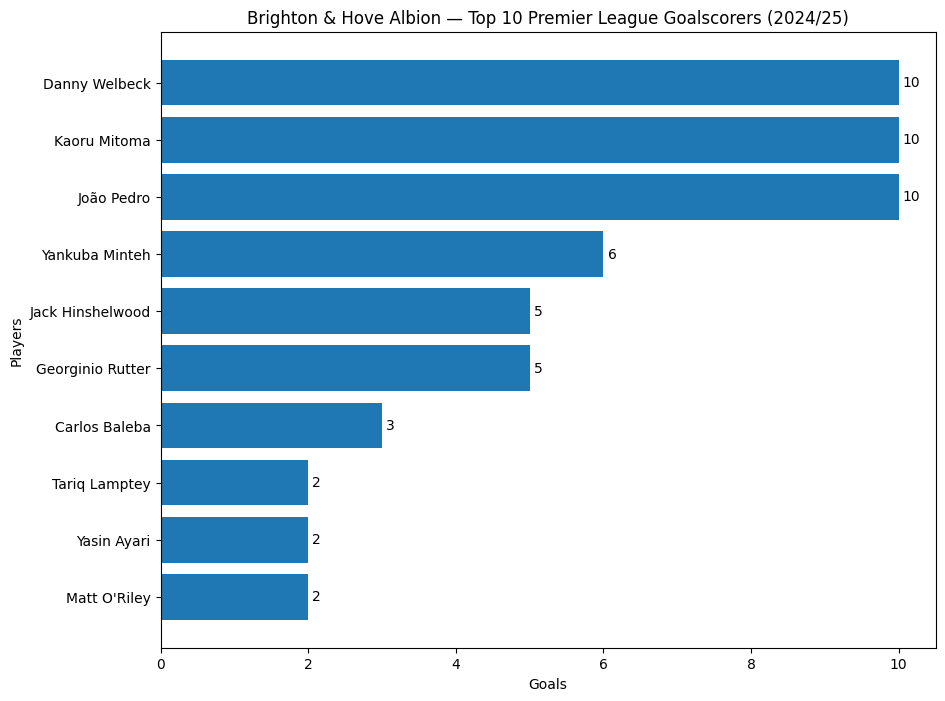

In [174]:
plt.figure(figsize=(10,8))
bars = plt.barh(top_10.Player, top_10.Gls)
plt.ylabel('Players')
plt.xlabel('Goals')
plt.title('Brighton & Hove Albion — Top 10 Premier League Goalscorers (2024/25)')
plt.bar_label(bars,padding=3)
plt.show()

In [175]:
brig = df.loc[(df.Squad=='Brighton') & (df.Pos!='GK'),['Player','Pos','Gls','xG']]
brig

,Player,Pos,Gls,xG
4,Simon Adingra,FW,2,2.5
39,Yasin Ayari,MF,2,2.4
44,Carlos Baleba,MF,3,3.1
89,Eiran Cashin,DF,0,0.0
152,Lewis Dunk,DF,0,0.8
165,Julio Enciso,MF,0,1.0
169,Pervis Estupiñán,DF,1,1.2
179,Evan Ferguson,FW,1,0.5
199,Billy Gilmour,MF,0,0.1
206,Diego Gómez,MF,1,0.9


In [176]:
gbp = brig.groupby('Pos')['Gls'].sum()
gbp

,Gls
Pos,
DF,6
FW,39
MF,19


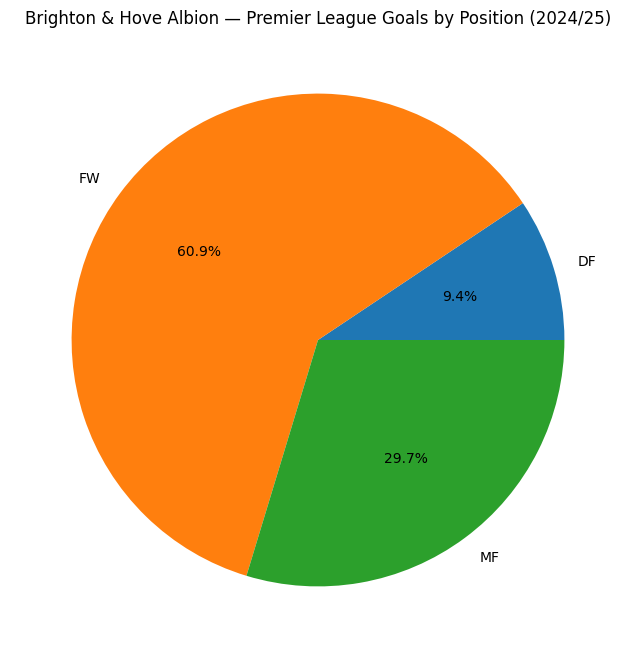

In [177]:
plt.figure(figsize=(10,8))
plt.pie(x=gbp.values,labels=gbp.index,autopct='%1.1f%%')
plt.title('Brighton & Hove Albion — Premier League Goals by Position (2024/25)')
plt.show()

In [178]:
df

,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,90s,...,Glsper90,Astper90,G+Aper90,G-PKper90,G+A-PKper90,xGper90,xAGper90,xG+xAGper90,npxGper90,npxG+xAGper90
0,Max Aarons,eng ENG,DF,Bournemouth,24.0,2000.0,3,1,86,1.0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,Joshua Acheampong,eng ENG,DF,Chelsea,18.0,2006.0,4,2,170,1.9,...,0.00,0.00,0.00,0.00,0.00,0.12,0.00,0.12,0.12,0.12
2,Tyler Adams,us USA,MF,Bournemouth,25.0,1999.0,28,21,1965,21.8,...,0.00,0.14,0.14,0.00,0.14,0.07,0.05,0.12,0.07,0.12
3,Tosin Adarabioyo,eng ENG,DF,Chelsea,26.0,1997.0,22,15,1409,15.7,...,0.06,0.06,0.13,0.06,0.13,0.06,0.01,0.07,0.06,0.07
4,Simon Adingra,ci CIV,FW,Brighton,22.0,2002.0,29,12,1097,12.2,...,0.16,0.16,0.33,0.16,0.33,0.20,0.20,0.40,0.20,0.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
569,Ashley Young,eng ENG,DF,Everton,39.0,1985.0,32,19,1875,20.8,...,0.05,0.14,0.19,0.05,0.19,0.01,0.11,0.12,0.01,0.12
570,Illia Zabarnyi,ua UKR,DF,Bournemouth,21.0,2002.0,36,35,3109,34.5,...,0.00,0.03,0.03,0.00,0.03,0.04,0.02,0.06,0.04,0.06
571,Oleksandr Zinchenko,ua UKR,DF,Arsenal,27.0,1996.0,15,5,527,5.9,...,0.00,0.17,0.17,0.00,0.17,0.11,0.03,0.14,0.11,0.14
572,Joshua Zirkzee,nl NED,FW,Manchester Utd,23.0,2001.0,32,14,1402,15.6,...,0.19,0.06,0.26,0.19,0.26,0.31,0.10,0.41,0.31,0.41


In [179]:
df['Group'] = df.Squad.apply(lambda x:'Brighton' if x == 'Brighton' else 'Other PL Clubs')
df.Group

,Group
0,Other PL Clubs
1,Other PL Clubs
2,Other PL Clubs
3,Other PL Clubs
4,Brighton
...,...
569,Other PL Clubs
570,Other PL Clubs
571,Other PL Clubs
572,Other PL Clubs


In [180]:
forward = df.loc[(df.Pos=='FW') & (df.Min > 900), ['Player','Squad','Pos','Min','Glsper90','Group']]
forward

,Player,Squad,Pos,Min,Glsper90,Group
4,Simon Adingra,Brighton,FW,1097,0.16,Brighton
30,Cameron Archer,Southampton,FW,1441,0.12,Other PL Clubs
33,Adam Armstrong,Southampton,FW,1248,0.14,Other PL Clubs
41,Jordan Ayew,Leicester City,FW,1638,0.27,Other PL Clubs
43,Leon Bailey,Aston Villa,FW,1139,0.08,Other PL Clubs
...,...,...,...,...,...,...
549,Danny Welbeck,Brighton,FW,2115,0.43,Brighton
559,Harry Wilson,Fulham,FW,1162,0.46,Other PL Clubs
562,Yoane Wissa,Brentford,FW,2919,0.59,Other PL Clubs
563,Chris Wood,Nott'ham Forest,FW,2959,0.61,Other PL Clubs


In [181]:
forward.Group.value_counts()

,count
Group,
Other PL Clubs,72
Brighton,5


In [182]:
import seaborn as sns

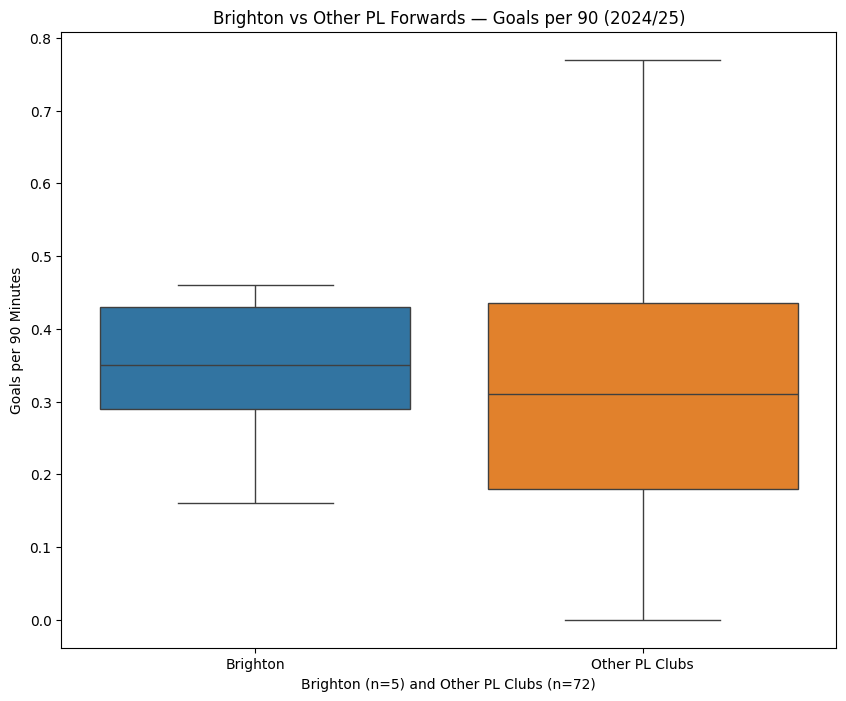

In [184]:
plt.figure(figsize=(10,8))
sns.boxplot(forward, x='Group', y='Glsper90', hue='Group')
plt.title('Brighton vs Other PL Forwards — Goals per 90 (2024/25)')
plt.xlabel('Brighton (n=5) and Other PL Clubs (n=72)')
plt.ylabel('Goals per 90 Minutes')
plt.show()

In [185]:
forward.groupby('Group')['Glsper90'].describe()

,count,mean,std,min,25%,50%,75%,max
Group,,,,,,,,
Brighton,5.0,0.338000,0.119875,0.16,0.29,0.35,0.430,0.46
Other PL Clubs,72.0,0.316667,0.184483,0.00,0.18,0.31,0.435,0.77
